# Лабораторная работа: пословный генератор текста на LSTM

## Обучение нейросети на нескольких книгах (токенизация по словам)

### Цель работы
Реализовать и обучить генеративную модель на основе LSTM, которая предсказывает
следующее **слово или знак препинания** (а не отдельный символ) и генерирует
текст в стиле загруженных книг.

Это вторая часть работы: в первой использовалась посимвольная модель. Здесь
единица предсказания крупнее, поэтому при том же окне контекста модель "видит"
значительно больше текста по смыслу, а слова не приходится собирать по буквам.
Обратная сторона: словарь уже не 70-160 символов, а десятки тысяч слов, и
редкие слова и формы приходится заменять служебным токеном `<unk>`.

В работе выполняются следующие этапы:
- загрузка, чистка и анализ текстового корпуса;
- токенизация по словам и построение словаря;
- разбиение на обучающую и валидационную выборки;
- архитектура LSTM с общими весами входа и выхода;
- обучение с разогревом learning rate и сглаживанием меток;
- анализ функции потерь и перплексии;
- генерация текста и эксперимент с параметрами сэмплинга (`top_k`, `top_p`).

In [1]:
import math
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

print("Версия PyTorch:", torch.__version__)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():  # GPU в чипах Apple Silicon
    device = "mps"
else:
    device = "cpu"

print("Устройство для вычислений:", device)
if device == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print(f"Память GPU: {props.total_memory / 1024**3:.1f} ГБ")
elif device != "cuda":
    print("GPU не найден: обучение будет очень медленным. "
          "В Colab включите T4 GPU в настройках среды выполнения.")

Версия PyTorch: 2.11.0+cu128
Устройство для вычислений: cuda
GPU: Tesla T4
Память GPU: 14.6 ГБ


## 1. Параметры эксперимента

Значения ниже - те, на которых реально проводилось обучение. Коротко, почему
они именно такие:

- **`VOCAB_SIZE = 32000`.** Чем больше словарь, тем меньше слов превращается
  в `<unk>`, но тем больше параметров у модели (эмбеддинг = `vocab_size × hidden_dim`).
- **`HIDDEN_DIM = 640`.** Подобран по числу параметров модели так, чтобы
  размер модели был соразмерен объёму корпуса (около 15,7 млн символов):
  при связанных весах входа/выхода эмбеддинг `vocab_size × hidden_dim`
  доминирует над остальными параметрами, и `hidden_dim` - главный рычаг,
  которым можно двигать общий размер модели при фиксированном словаре.
- **`WARMUP_STEPS`, `LABEL_SMOOTHING`, честное разбиение `VAL_CHUNKS`** - все
  три добавлены после экспериментов с более ранней версией модели, где
  `val loss` вёл себя шумно, а обучение могло остановиться слишком рано.
- **Параметры сэмплинга (`TOP_K=70`, `TOP_P=0.73`, штраф за повтор)** - подобраны
  эмпирически: `top_p=0.5` давал зацикливание ("не могу, не могу..."),
  `top_p=0.92` - разнообразно, но местами бессвязно. Подробный разбор - в
  разделе с экспериментом ниже.

In [ ]:
BOOKS_DIR = "books"          # папка с книгами в формате .txt
CHECKPOINT = "lstm_word.pt"  # внутри файла же хранится словарь, отдельный токенизатор не нужен

# Словарь
VOCAB_SIZE = 32000     # сколько самых частых токенов входит в словарь (плюс <unk>)
MIN_CHAR_COUNT = 100   # редкие символы (латиница, экзотические знаки) удаляются из текста

# Модель
HIDDEN_DIM = 640   # размер памяти LSTM (он же размер эмбеддингов: веса входа и выхода общие)
NUM_LAYERS = 2
DROPOUT = 0.45    

# Обучение
SEQ_LEN = 192      # длина окна в токенах (слово или знак препинания)
BATCH_SIZE = 48    
LEARNING_RATE = 1e-3
MAX_STEPS = 12000          
WARMUP_STEPS = 250           # плавный разгон learning rate в начале обучения
EVAL_EVERY = 100             # как часто проверять loss на валидации
EVAL_BATCHES = 40            # на скольких батчах считать val loss (больше - меньше шума)
PATIENCE = 12                # остановиться, если val loss не улучшался столько проверок подряд
VAL_FRACTION = 0.05
VAL_CHUNKS = 100   # книга режется на столько кусков; чем больше VAL_CHUNKS относительно
                   # 1/VAL_FRACTION, тем равномернее валидационные куски разбросаны по книге
LABEL_SMOOTHING = 0.05  # смягчает уверенность модели, снижает риск зацикливания

# Генерация
MAX_NEW_TOKENS = 150
TEMPERATURE = 0.8
TOP_K = 70          # выбирать только из K самых вероятных токенов (top-p сужает дальше)
TOP_P = 0.73        # nucleus-сэмплинг: минимальный набор токенов с суммарной вероятностью TOP_P
NO_REPEAT_NGRAM = 4     # запрет повторять одну и ту же цепочку из 4 токенов подряд
REPETITION_PENALTY = 1.2   # штраф за уже использованные "содержательные" слова
REPETITION_WINDOW = 45     # окно в токенах, в котором отслеживаются повторы
PENALTY_EXEMPT_RANK = 450  # столько самых частых токенов не штрафуются (местоимения, предлоги)

SEED_TEXT = "Однажды вечером"  # начало текста для примеров генерации

## 2. Токенизация: регулярное выражение вместо готового токенизатора

Слова и знаки препинания выделяются одним регулярным выражением, без внешних
библиотек вроде sentencepiece:
- буквенное слово (с внутренними дефисами/апострофами, напр. "кто-то");
- число;
- многоточие "..." как один токен;
- перевод строки как отдельный токен (так сохраняется разбиение на абзацы);
- любой другой одиночный символ - это знак препинания, тире или кавычка.

In [3]:
TOKEN_RE = re.compile(
    r"\n"
    r"|\.\.\."
    r"|[A-Za-zА-Яа-яЁё]+(?:[-'][A-Za-zА-Яа-яЁё]+)*"
    r"|[0-9]+"
    r"|[^\sA-Za-zА-Яа-яЁё0-9]"
)

UNK = "<unk>"
NO_SPACE_BEFORE = set(".,!?;:)]}»%") | {"...", "…"}
NO_SPACE_AFTER = set("([{«")


def tokenize(text):
    return TOKEN_RE.findall(text)


def detokenize(tokens):
    """Склеивает токены обратно в текст, расставляя пробелы по простым правилам."""
    out = []
    suppress_space = True
    for tok in tokens:
        if tok == "\n":
            out.append("\n")
            suppress_space = True
            continue
        if out and not suppress_space and tok not in NO_SPACE_BEFORE:
            out.append(" ")
        out.append(tok)
        suppress_space = tok in NO_SPACE_AFTER
    return "".join(out)


# Проверка на примере: токенизация и обратная склейка должны давать исходный текст
demo = "— Вы знаете, — сказал Левин, что он не придёт... Она молчала.\n\n«Хорошо», — ответила она."
demo_tokens = tokenize(demo)
print("Токены:", demo_tokens[:15], "...")
print("\nВосстановлено:", repr(detokenize(demo_tokens)))
print("Совпадает с оригиналом:", detokenize(demo_tokens) == demo)

Токены: ['—', 'Вы', 'знаете', ',', '—', 'сказал', 'Левин', ',', 'что', 'он', 'не', 'придёт', '...', 'Она', 'молчала'] ...

Восстановлено: '— Вы знаете, — сказал Левин, что он не придёт... Она молчала.\n\n«Хорошо», — ответила она.'
Совпадает с оригиналом: True


## 3. Загрузка корпуса

Книги должны лежать в папке `books/` в формате `.txt`. Если папка пуста, ячейка
предложит загрузить файлы с компьютера (работает в Colab).

In [4]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/lstm

Mounted at /content/drive
/content/drive/MyDrive/lstm


In [5]:
import os

os.makedirs(BOOKS_DIR, exist_ok=True)

if not list(Path(BOOKS_DIR).glob("*.txt")):
    try:
        from google.colab import files
        print("Выберите .txt файлы с книгами:")
        uploaded = files.upload()
        for name, data in uploaded.items():
            with open(os.path.join(BOOKS_DIR, name), "wb") as f:
                f.write(data)
    except ImportError:
        print(f"Положите .txt файлы в папку '{BOOKS_DIR}' и запустите ячейку снова.")

print("Файлы в папке с книгами:", [p.name for p in sorted(Path(BOOKS_DIR).glob("*.txt"))])

Файлы в папке с книгами: ['besi.txt', 'brotherskaramaz.txt', 'bunin.txt', 'dvoreanskoegnezdo.txt', 'gogol.txt', 'kreicevorasonata.txt', 'nakanune.txt', 'otciideti.txt', 'prestnakaz.txt', 'tihiidon.txt', 'tolstoi.txt', 'tolstoiwarpeace.txt', 'turgenev.txt', 'voskresenie.txt']


## 4. Чистка текста

Помимо базовой нормализации (пробелы, единый вид тире), сюда добавлены четыре
правила, которые понадобились на практике при работе с текстами классики:

- **номера страниц** - строки, целиком состоящие из цифр;
- **заголовки глав из римских цифр** (например, "VII") - без этого правила
  токенизация принимает их за настоящие английские слова, и модель начинает
  вставлять в текст случайные псевдозаголовки;
- **сноски** вида `[12]`;
- **разделители сцен** вроде "* * *";
- **задвоенная пунктуация** вроде "кажется,," - типичный огрех исходных `.txt`.

In [6]:
def read_book(path):
    for enc in ("utf-8", "cp1251"):
        try:
            return path.read_text(encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Не удалось определить кодировку: {path}")


# Строка, целиком состоящая из римской цифры (обычно - заголовок главы вроде "VII").
# (?=[MDCLXVI]) в начале не даёт регэкспу случайно "проглотить" пустую строку.
ROMAN_CHAPTER_LINE = re.compile(
    r"(?im)^[ \t]*(?=[MDCLXVI])M{0,4}(CM|CD|D?C{0,3})(XC|XL|L?X{0,3})(IX|IV|V?I{0,3})[ \t]*\n"
)
FOOTNOTE_REF = re.compile(r"\[\d{1,3}\]")
SCENE_BREAK = re.compile(r"(?m)^[ \t]*\*(?:[ \t]*\*)+[ \t]*\n?")
DUP_PUNCT = re.compile(r"([,;:])\1+")


def clean(text):
    text = text.replace("\r\n", "\n").replace("\xa0", " ")
    text = text.replace("–", "—").replace("−", "—")
    text = re.sub(r"(?m)^[ \t]*\d+[ \t]*\n", "", text)  # номера страниц
    text = ROMAN_CHAPTER_LINE.sub("", text)             # заголовки глав вида "VII"
    text = FOOTNOTE_REF.sub("", text)                   # сноски вида [12]
    text = SCENE_BREAK.sub("", text)                    # разделители сцен "* * *"
    text = DUP_PUNCT.sub(r"\1", text)                   # двойная пунктуация вроде ",,"
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def load_books(folder):
    files_list = sorted(Path(folder).glob("*.txt"))
    if not files_list:
        raise SystemExit(f"В папке '{folder}' нет .txt файлов")
    bks = []
    for f in files_list:
        t = clean(read_book(f))
        print(f"{f.name}: {len(t):,} символов")
        bks.append(t)
    return bks


books = load_books(BOOKS_DIR)

# Убираем редкие символы (латиница, экзотические знаки): они только раздувают словарь
counts_ch = Counter("".join(books))
rare = "".join(c for c, n in counts_ch.items() if n < MIN_CHAR_COUNT)
if rare:
    table = str.maketrans("", "", rare)
    books = [b.translate(table) for b in books]
    print(f"\nУдалено редких символов: {len(rare)}")

total_chars = sum(len(b) for b in books)
print(f"\nВсего символов: {total_chars:,}")

besi.txt: 1,277,625 символов
brotherskaramaz.txt: 1,815,396 символов
bunin.txt: 514,612 символов
dvoreanskoegnezdo.txt: 305,525 символов
gogol.txt: 765,989 символов
kreicevorasonata.txt: 937,382 символов
nakanune.txt: 281,392 символов
otciideti.txt: 371,699 символов
prestnakaz.txt: 1,074,580 символов
tihiidon.txt: 2,884,831 символов
tolstoi.txt: 955,899 символов
tolstoiwarpeace.txt: 3,003,248 символов
turgenev.txt: 657,710 символов
voskresenie.txt: 894,073 символов

Удалено редких символов: 44

Всего символов: 15,738,635


## 5. Диагностика: иноязычные вставки

В классических текстах (особенно у Толстого) встречаются целые реплики на
французском. Это не всегда мусор - иногда это осмысленная часть сцены (светская
речь персонажей), поэтому вместо того, чтобы автоматически всё вырезать, сначала
выводится отчёт: сколько в корпусе слов из латинских букв и какие встречаются
чаще всего. Если доля большая и это явно случайные вставки - можно включить
`DROP_FOREIGN_PARAGRAPHS`, и абзацы с преобладанием латиницы будут удалены целиком.

In [7]:
DROP_FOREIGN_PARAGRAPHS = False  # включите, если отчёт ниже покажет много иноязычного текста
FOREIGN_LATIN_RATIO = 0.4


def report_latin_words(bks, top_n=30):
    latin_word = re.compile(r"[A-Za-z]+")
    cnt = Counter()
    total_words = 0
    for b in bks:
        for tok in tokenize(b):
            if tok == "\n" or not tok.strip():
                continue
            total_words += 1
            if latin_word.fullmatch(tok):
                cnt[tok] += 1
    total_latin = sum(cnt.values())
    share = total_latin / total_words if total_words else 0
    print(f"Слов из латинских букв: {total_latin:,} из {total_words:,} ({share:.2%})")
    if cnt:
        print(f"Самые частые ({top_n}):")
        for w, n in cnt.most_common(top_n):
            print(f"  {w!r}: {n}")


def drop_foreign_paragraphs(text):
    cyr = re.compile(r"[А-Яа-яЁё]")
    lat = re.compile(r"[A-Za-z]")
    kept = []
    for para in text.split("\n\n"):
        n_cyr, n_lat = len(cyr.findall(para)), len(lat.findall(para))
        if n_lat and n_lat / max(n_cyr + n_lat, 1) > FOREIGN_LATIN_RATIO:
            continue
        kept.append(para)
    return "\n\n".join(kept)


report_latin_words(books)
if DROP_FOREIGN_PARAGRAPHS:
    books = [drop_foreign_paragraphs(b) for b in books]
    print(f"\nПосле удаления иноязычных абзацев: {sum(len(b) for b in books):,} символов")

Слов из латинских букв: 22,847 из 3,165,038 (0.72%)
Самые частые (30):
  'de': 756
  'est': 386
  'et': 375
  'vous': 355
  'la': 355
  'c': 335
  'l': 330
  'le': 322
  'que': 317
  'd': 256
  'a': 235
  'n': 222
  'un': 213
  'les': 213
  'je': 205
  're': 204
  'mon': 199
  'pas': 185
  'ne': 185
  's': 183
  'il': 178
  'm': 160
  'en': 157
  'me': 153
  'Lise': 148
  'des': 141
  'ce': 135
  'une': 132
  'qu': 128
  'qui': 127


## 6. Построение словаря

Весь корпус токенизируется, а словарь строится из `VOCAB_SIZE` самых частых
токенов. Всё, что не попало в словарь (редкие слова, формы, опечатки, имена),
при кодировании заменяется на служебный токен `<unk>`. Доля `<unk>` - главный
показатель того, хватает ли словаря для этого объёма текста.

In [8]:
def build_vocab(tokens):
    cnt = Counter(t for t in tokens if t != "\n")
    most_common = [w for w, _ in cnt.most_common(VOCAB_SIZE - 2)]
    vcb = ["\n", UNK] + most_common  # "\n" и <unk> - всегда в словаре
    return vcb, {w: i for i, w in enumerate(vcb)}


def encode(tokens, stoi):
    unk_id = stoi[UNK]
    return [stoi.get(t, unk_id) for t in tokens]


all_tokens = tokenize("\n\n".join(books))
print(f"Всего токенов (слов и знаков): {len(all_tokens):,}")

vocab, stoi = build_vocab(all_tokens)
unk_rate = sum(1 for t in all_tokens if t not in stoi) / len(all_tokens)

print(f"Размер словаря: {len(vocab):,}")
print(f"Доля токенов, заменяемых на <unk>: {unk_rate:.1%}")
print("\nСамые частые токены словаря:", vocab[2:12])

Всего токенов (слов и знаков): 3,280,545
Размер словаря: 32,000
Доля токенов, заменяемых на <unk>: 8.5%

Самые частые токены словаря: [',', '.', 'и', '—', 'в', 'не', 'что', 'на', '?', 'с']


## 7. Разбиение на обучающую и валидационную выборки

Наивный вариант - отдавать в валидацию последние 5% каждой книги - был бы
нечестным: это буквально развязка сюжета и эпилог, а не случайный срез текста.
Вместо этого книга режется на `VAL_CHUNKS` равных кусков, и в валидацию уходит
каждый `(1/VAL_FRACTION)`-й из них - то есть несколько небольших фрагментов,
равномерно разбросанных по всей книге (например, на 0%, 20%, 40%, 60% и 80%
её длины), а не один большой кусок в конце.

In [9]:
def split_train_val(book, n_chunks=VAL_CHUNKS, val_fraction=VAL_FRACTION):
    chunk_len = len(book) // n_chunks
    if chunk_len == 0:
        return book, ""
    val_every = max(1, round(1 / val_fraction))
    train_parts, val_parts = [], []
    for i in range(n_chunks):
        start = i * chunk_len
        end = len(book) if i == n_chunks - 1 else start + chunk_len
        chunk = book[start:end]
        (val_parts if i % val_every == 0 else train_parts).append(chunk)
    return "\n\n".join(train_parts), "\n\n".join(val_parts)


train_parts, val_parts = [], []
for b in books:
    tr, va = split_train_val(b)
    train_parts.append(tr)
    val_parts.append(va)

train_ids = encode(tokenize("\n\n".join(train_parts)), stoi)
val_ids = encode(tokenize("\n\n".join(val_parts)), stoi)

train_data = torch.tensor(train_ids, dtype=torch.long)
val_data = torch.tensor(val_ids, dtype=torch.long)

print(f"Токенов в обучающей выборке: {len(train_data):,}")
print(f"Токенов в валидационной выборке: {len(val_data):,} "
      f"({len(val_data) / (len(train_data) + len(val_data)):.1%})")

if len(val_data) <= SEQ_LEN + 1:
    raise SystemExit("Текста слишком мало: добавьте книги или уменьшите SEQ_LEN")

Токенов в обучающей выборке: 3,120,580
Токенов в валидационной выборке: 163,612 (5.0%)


## 8. Обучающие последовательности: пары «вход — цель»

Как и в посимвольной версии, модель учится на случайных окнах длиной `SEQ_LEN`
токенов: вход - окно без последнего токена, цель - то же окно, сдвинутое на
один токен вперёд. Разница лишь в том, что здесь один токен - это целое слово
или знак препинания, а не буква, поэтому то же окно в 192 токена охватывает
заметно больше текста по смыслу, чем 192 символа.

In [10]:
def get_batch(data, dev):
    ix = torch.randint(len(data) - SEQ_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([data[i:i + SEQ_LEN] for i in ix])
    y = torch.stack([data[i + 1:i + SEQ_LEN + 1] for i in ix])
    return x.to(dev), y.to(dev)


x_demo, y_demo = get_batch(train_data, "cpu")
print("Форма батча (примеров, токенов в окне):", tuple(x_demo.shape))

print("\nВХОД (первые 20 токенов):")
print(detokenize([vocab[i] for i in x_demo[0][:20].tolist()]))
print("\nЦЕЛЬ (тот же текст, сдвинутый на 1 токен):")
print(detokenize([vocab[i] for i in y_demo[0][:20].tolist()]))

Форма батча (примеров, токенов в окне): (48, 192)

ВХОД (первые 20 токенов):
он, став <unk>:
— Забыл тебе сказать. Меркулова нашего помнишь? <unk>? то?


ЦЕЛЬ (тот же текст, сдвинутый на 1 токен):
, став <unk>:
— Забыл тебе сказать. Меркулова нашего помнишь? <unk>? то?
—


## 9. Архитектура модели

- **Embedding** переводит номер токена в вектор размерности `hidden_dim`.
- **LSTM** (`NUM_LAYERS` слоёв) читает последовательность и накапливает контекст.
- **Linear** на выходе выдаёт оценку для каждого токена словаря.
- **Общие веса входа и выхода** (`fc.weight = embed.weight`): при словаре
  в десятки тысяч слов это заметно сокращает число параметров и снижает
  переобучение, а при таком связывании размер эмбеддинга обязан совпадать
  с `hidden_dim` LSTM.

In [11]:
class WordLSTM(nn.Module):
    def __init__(self, vocab_size, hidden_dim, num_layers, dropout):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, hidden_dim)
        nn.init.uniform_(self.embed.weight, -0.1, 0.1)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers,
                            batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.fc.weight = self.embed.weight  # общие веса входа и выхода

    def forward(self, x, state=None):
        out, state = self.lstm(self.drop(self.embed(x)), state)
        return self.fc(self.drop(out)), state


config = dict(vocab_size=len(vocab), hidden_dim=HIDDEN_DIM,
              num_layers=NUM_LAYERS, dropout=DROPOUT)
model = WordLSTM(**config).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nЧисло обучаемых параметров: {n_params:,}")

# Проверка формы выхода
x_check, y_check = get_batch(train_data, device)
with torch.no_grad():
    logits_check, _ = model(x_check)
print("\nФорма входа: ", tuple(x_check.shape))
print("Форма выхода:", tuple(logits_check.shape), "= (примеров, токенов, размер словаря)")

WordLSTM(
  (embed): Embedding(32000, 640)
  (drop): Dropout(p=0.45, inplace=False)
  (lstm): LSTM(640, 640, num_layers=2, batch_first=True, dropout=0.45)
  (fc): Linear(in_features=640, out_features=32000, bias=True)
)

Число обучаемых параметров: 27,075,840

Форма входа:  (48, 192)
Форма выхода: (48, 192, 32000) = (примеров, токенов, размер словаря)


## 10. Функция потерь

Предсказание следующего токена - многоклассовая классификация, используется
перекрёстная энтропия. До обучения веса случайны, поэтому потери должны быть
близки к `ln(размер словаря)` - сильное расхождение сигнализировало бы об
ошибке в данных или модели.

In [12]:
with torch.no_grad():
    initial_loss = F.cross_entropy(
        logits_check.reshape(-1, logits_check.size(-1)), y_check.reshape(-1)
    ).item()

print(f"Начальные потери модели:    {initial_loss:.3f}")
print(f"Ожидаемое значение ln(|V|): {math.log(len(vocab)):.3f}")

Начальные потери модели:    10.378
Ожидаемое значение ln(|V|): 10.373


## 11. Оптимизатор, разогрев learning rate и сглаживание меток

- **AdamW** со скоростью обучения `LEARNING_RATE` и weight decay.
- **Разогрев + косинусное затухание.** Первые `WARMUP_STEPS` шагов скорость
  обучения растёт линейно от 0 до полной, а дальше плавно затухает по косинусу.
  Без разогрева обучение в первых прогонах шло рывками (`train loss` дёргался);
  график ниже показывает форму этого расписания.
- **Label smoothing (`LABEL_SMOOTHING=0.05`)** применяется только к функции
  потерь на обучении - он смягчает уверенность модели в самых предсказуемых
  продолжениях и немного снижает риск зацикливания при генерации. Для оценки
  на валидации используется обычная перекрёстная энтропия без сглаживания,
  чтобы `val loss` оставался понятной, сравнимой между прогонами величиной.

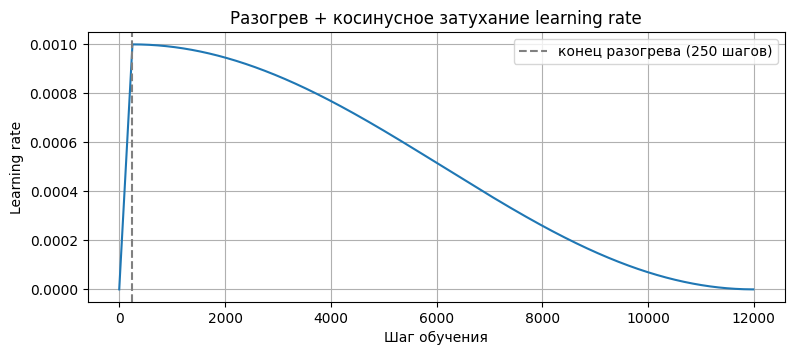

In [13]:
def lr_lambda(step):
    if step < WARMUP_STEPS:
        return step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))


steps_axis = np.arange(0, MAX_STEPS, 10)
lr_curve = [lr_lambda(s) * LEARNING_RATE for s in steps_axis]

plt.figure(figsize=(9, 3.5))
plt.plot(steps_axis, lr_curve)
plt.axvline(WARMUP_STEPS, color="gray", linestyle="--", label=f"конец разогрева ({WARMUP_STEPS} шагов)")
plt.xlabel("Шаг обучения")
plt.ylabel("Learning rate")
plt.title("Разогрев + косинусное затухание learning rate")
plt.legend()
plt.grid(True)
plt.show()

## 12. Генерация текста: сэмплинг

Функция `sample` продолжает текст по одному токену за раз и совмещает
несколько механизмов, которые мы добавляли по мере того, как находили
конкретные проблемы в сгенерированном тексте:

- **`temperature`** - делает распределение вероятностей острее (ниже) или
  более плоским (выше).
- **`top_k`** - оставляет только K самых вероятных токенов.
- **`top_p` (nucleus-сэмплинг)** - оставляет минимальный набор токенов с
  суммарной вероятностью `top_p`; подстраивается под форму распределения
  лучше, чем фиксированный `top_k`.
- **Запрет повтора n-грамм (`NO_REPEAT_NGRAM`)** - не даёт буквально повторить
  уже сгенерированную цепочку из 4 токенов подряд.
- **Штраф за повтор (`REPETITION_PENALTY`)** - дополнительно снижает шанс
  "содержательных" слов, уже встречавшихся в недавнем тексте (окно
  `REPETITION_WINDOW`), не трогая самые частые служебные слова и знаки
  препинания (`PENALTY_EXEMPT_RANK`) - иначе штраф ломает грамматику
  (нельзя же штрафовать "и", "не", запятую).
- `<unk>` никогда не генерируется явно.

In [14]:
@torch.no_grad()
def sample(model, vocab, stoi, device, prompt="", n_tokens=MAX_NEW_TOKENS,
           temperature=TEMPERATURE, top_k=TOP_K, top_p=TOP_P):
    model.eval()
    unk_id = stoi[UNK]

    ids = encode(tokenize(prompt), stoi) or [stoi["\n"]]
    logits, state = model(torch.tensor([ids], device=device))
    out = list(ids)

    exempt = set(range(min(PENALTY_EXEMPT_RANK, len(vocab))))
    n = NO_REPEAT_NGRAM
    seen = {}

    def remember(seq):
        if n and len(seq) >= n:
            seen.setdefault(tuple(seq[-n:-1]), set()).add(seq[-1])

    for k in range(1, len(out) + 1):
        remember(out[:k])

    for _ in range(n_tokens):
        scores = logits[0, -1] / temperature
        scores[unk_id] = float("-inf")

        if REPETITION_PENALTY and REPETITION_PENALTY != 1.0:
            recent = set(out[-REPETITION_WINDOW:]) - exempt
            for t in recent:
                scores[t] = scores[t] / REPETITION_PENALTY if scores[t] > 0 else scores[t] * REPETITION_PENALTY

        if n:
            forbidden = seen.get(tuple(out[-(n - 1):]))
            if forbidden:
                scores[list(forbidden)] = float("-inf")
        if top_k:
            kth = torch.topk(scores, top_k).values[-1]
            scores = scores.masked_fill(scores < kth, float("-inf"))
        if top_p and top_p < 1.0:
            sorted_scores, sorted_idx = torch.sort(scores, descending=True)
            cum_probs = torch.cumsum(F.softmax(sorted_scores, dim=-1), dim=-1)
            cutoff = (cum_probs >= top_p).nonzero()
            if len(cutoff):
                drop_idx = sorted_idx[cutoff[0].item() + 1:]
                scores[drop_idx] = float("-inf")

        nxt = torch.multinomial(F.softmax(scores, dim=-1), 1).item()
        out.append(nxt)
        remember(out)
        logits, state = model(torch.tensor([[nxt]], device=device), state)

    return detokenize([vocab[i] for i in out])

## 13. Обучение модели

Каждые `EVAL_EVERY` шагов считаются потери на валидации, перплексия и печатается
короткий пример генерации. Лучшая версия модели сохраняется автоматически;
обучение останавливается раньше `MAX_STEPS`, если `val loss` не улучшался
`PATIENCE` проверок подряд.

In [15]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


@torch.no_grad()
def evaluate(model, data, device, n_batches=EVAL_BATCHES):
    model.eval()
    losses = []
    for _ in range(n_batches):
        x, y = get_batch(data, device)
        logits, _ = model(x)
        losses.append(F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1)).item())
    model.train()
    return sum(losses) / len(losses)


history = {"step": [], "train_loss": [], "val_loss": []}
best_val, best_step, bad_evals = float("inf"), 0, 0
running_loss, running_n = torch.zeros((), device=device), 0

model.train()
for step in range(1, MAX_STEPS + 1):
    x, y = get_batch(train_data, device)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
        logits, _ = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), y.reshape(-1),
                               label_smoothing=LABEL_SMOOTHING)

    optimizer.zero_grad()
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()

    running_loss += loss.detach()
    running_n += 1

    if step % EVAL_EVERY == 0:
        train_loss = (running_loss / running_n).item()
        val_loss = evaluate(model, val_data, device)
        running_loss.zero_()
        running_n = 0

        history["step"].append(step)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(f"шаг {step:>5}/{MAX_STEPS}: train loss {train_loss:.3f}, "
              f"val loss {val_loss:.3f}, перплексия {math.exp(val_loss):.2f}")
        print("   Пример:", sample(model, vocab, stoi, device, SEED_TEXT, n_tokens=60).replace("\n", " ⏎ "))
        model.train()  # sample() переключил модель в eval() - возвращаем обратно

        if val_loss < best_val:
            best_val, best_step, bad_evals = val_loss, step, 0
            torch.save({"model": model.state_dict(), "vocab": vocab, "config": config}, CHECKPOINT)
            print(f"   Лучшая модель сохранена в '{CHECKPOINT}'")
        else:
            bad_evals += 1
            if bad_evals >= PATIENCE:
                print("\nVal loss перестал улучшаться, останавливаю обучение.")
                break

print(f"\nГотово. Лучший val loss: {best_val:.3f} (шаг {best_step})")

шаг   100/12000: train loss 8.387, val loss 6.506, перплексия 669.12
   Пример: Однажды вечером то от на?... не ⏎ . ⏎  ⏎ ...,., ⏎ — ⏎ — — в не,,, ⏎  ⏎ , в., ⏎  ⏎ .,, ⏎ ,. что,,,. —, ⏎ , ⏎ —. и ⏎  ⏎ ,,,
   Лучшая модель сохранена в 'lstm_word.pt'
шаг   200/12000: train loss 6.648, val loss 6.020, перплексия 411.38
   Пример: Однажды вечером по — я не он, как как. ⏎  ⏎ — Ну, я, как ты, я это, он в я. ⏎  ⏎ И! «— Да! — — Я не не я. ⏎ — — — Я, что бы не не, как, я не сказал, — не
   Лучшая модель сохранена в 'lstm_word.pt'
шаг   300/12000: train loss 6.305, val loss 5.737, перплексия 310.01
   Пример: Однажды вечером — а сказал, что он в меня, но я не все. ⏎  ⏎ — Я ты не это, а вы меня, что он, что что я бы не будет? — сказал я? ⏎  ⏎ — А я вы, как он не я, и он, а что не не я
   Лучшая модель сохранена в 'lstm_word.pt'
шаг   400/12000: train loss 6.068, val loss 5.569, перплексия 262.15
   Пример: Однажды вечером и и не может, что я мог не может, не так. ⏎  ⏎ — Да, и я вы, что это? — крикну

## 14. Анализ функции потерь

Если потери на обучении продолжают падать, а на валидации начинают расти -
это признак переобучения. Сравнение с посимвольной моделью: там `train loss`
и `val loss` почти совпадали, а здесь, при словаре в десятки тысяч слов,
определённый разрыв между ними ожидаем и не обязательно означает переобучение.

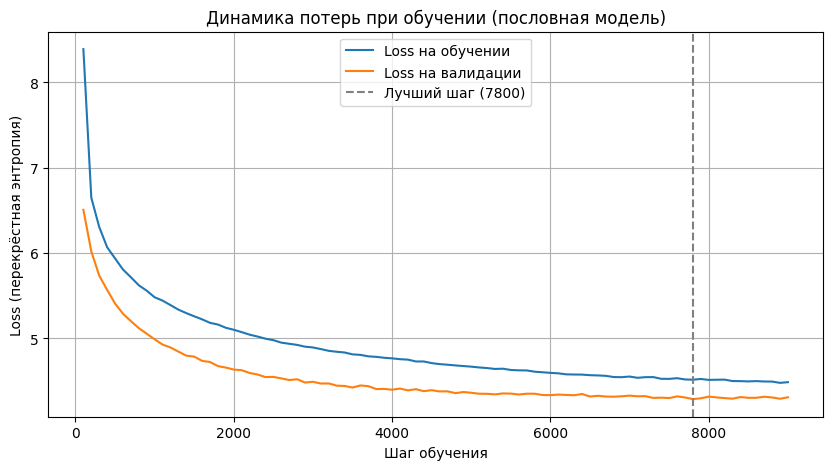

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Loss на обучении")
plt.plot(history["step"], history["val_loss"], label="Loss на валидации")
plt.axvline(best_step, color="gray", linestyle="--", label=f"Лучший шаг ({best_step})")
plt.xlabel("Шаг обучения")
plt.ylabel("Loss (перекрёстная энтропия)")
plt.title("Динамика потерь при обучении (пословная модель)")
plt.legend()
plt.grid(True)
plt.show()

## 15. Лучший шаг и перплексия

`Perplexity = exp(loss)` - сколько токенов модель в среднем считает одинаково
вероятными кандидатами на следующую позицию. Из-за большого словаря (32 000
против 70-160 символов) перплексия здесь по конструкции заметно выше, чем у
посимвольной модели, и напрямую их сравнивать нельзя - это разные единицы
измерения одной и той же по сути задачи.

In [17]:
best_perplexity = math.exp(best_val)
print("Лучший шаг:", best_step)
print("Лучший loss на валидации:", round(best_val, 4))
print("Перплексия на валидации:", round(best_perplexity, 2))
print(f"Для сравнения: при случайном угадывании из {len(vocab):,} слов "
      f"перплексия была бы {len(vocab):,}.")

Лучший шаг: 7800
Лучший loss на валидации: 4.2897
Перплексия на валидации: 72.95
Для сравнения: при случайном угадывании из 32,000 слов перплексия была бы 32,000.


## 16. Загрузка лучшей модели

Вместе с весами в файле хранится и словарь, поэтому этот шаг работает и в
новой сессии - нужно только заново выполнить ячейки с определениями
`WordLSTM`, `tokenize`, `detokenize`, `sample` и параметрами выше.

In [18]:
ckpt = torch.load(CHECKPOINT, map_location=device)

vocab = ckpt["vocab"]
stoi = {w: i for i, w in enumerate(vocab)}

best_model = WordLSTM(**ckpt["config"]).to(device)
best_model.load_state_dict(ckpt["model"])
best_model.eval()

print("Лучшая модель загружена. Размер словаря:", len(vocab))

Лучшая модель загружена. Размер словаря: 32000


## 17. Пример генерации

In [19]:
print(sample(best_model, vocab, stoi, device, SEED_TEXT, n_tokens=250))

Однажды вечером, когда она уже сидела в горнице, она стояла в дверях, в комнате, в сенцах, с засученными рукавами на руке.
— Ты чего?
— В Вешках.
— Ну, а ты, — сказала она, — а то ты, может, не будешь ходить, а то я тебя не хочу.
— Нет, не могу.
— Я тебе говорю, что ты не хочешь, а ты не думай, что ты у меня не то что…
— И что ты?
— Ты не знаешь, а я не хочу, чтобы я зараз же пойду, а я тебя не знаю, и я тебя не верю…
— А ты, бабушка, не могу понять, что это ты? — Григорий нахмурился. — Я за что? то, я тебе не хочу…
— Я с тобой не поеду, я не пойду.
— А тебе что?
— Нет.
— Так ты что? — с досадой спросил Прохор.
— Да, — ответил Григорий, — я не понимаю, что ты в этом будешь.
— Как же ты мне говоришь? — сказал Григорий.
— Не буду.
— И чего же ты, брат, не знаешь?
— Да ты что?



## 18. Эксперимент с параметром `top_p`

В посимвольной модели мы разбирали эффект от `temperature`. Здесь - аналогичный
по сути эксперимент, но с `top_p` (nucleus-сэмплинг): он ограничивает выбор не
по абсолютной вероятности каждого токена, а по накопленной сумме вероятностей.

Тексты ниже - результат реального запуска на этой самой обученной модели
(корпус 15,7 млн символов, `val loss` 4,290), один и тот же промпт
("Однажды вечером") и одно и то же зерно генератора случайных чисел,
меняется только `top_k`/`top_p`.

### top_p = 0,5 (top_k = 40)

```
Однажды вечером, в воскресенье, он, как и всегда, был в доме, а в Петербурге, в Петербурге,
не в духе, а в Москве, в Петербурге.

— Да, я очень рад, — сказал он, — но я не могу знать, что вы не знаете, что я не могу.

Анна Павловна улыбнулась, но не могла понять, что она сказала.

«Да, это так, — думал он, — что я могу сказать ей, что я люблю его, и что я знаю, что я могу
сделать. И я не могу не любить ее. Я не могу верить этому. И я чувствую, что я понимаю ее, но
не могу, чтобы я не могу этого сделать. Я не хочу говорить о том, что я хочу, но я не хочу
жить, не могу».
```

**Наблюдения:** узкий выбор кандидатов приводит к двум видам зацикливания -
сначала на географическом названии ("в Петербурге" трижды подряд), затем на
обороте "я не могу" (пять раз в одном абзаце). Каждая фраза по отдельности
грамматически верна, но вместе они не двигают мысль вперёд.

### top_p = 0,73 (top_k = 70) - выбранное в итоге значение

```
Однажды вечером утром после отъезда в станицу к Мелеховым на квартире Григорий вернулся к
Петру Петровичу.
— Это он не, не может, — сказал Григорий. — А ты, знаешь, не стал на тебя?
— А?
— Да? то…
— А ты чего ж молчишь?
— Я не знаю.
— Да ты что же, Пантелевич, что я с тобой не говорю?
— Ну, так я, думаю, не знаю. А то я тебя знаю.
Григорий, не снимая фуражки, с трудом оттолкнул ее, крикнул:
— Ну что ж, ты и не хочешь, чтоб я в самом деле не думал? — спросил он, бледнея, и уже не
дожидаясь ответа, сказал: — Ты мне не трогай, что ты его, не шуми, не знаю, что ты меня не
понимаешь. Я тебе в тягость…
```

**Наблюдения:** персонажи и место действия остаются в одном произведении
("Тихий Дон" - Григорий, Мелеховы, Пантелевич), диалог живой, с характерными
для этого романа рублеными репликами. Первые два слова ("вечером утром") -
единственная явная нестыковка.

### top_p = 0,92 (top_k = 60)

```
Однажды вечером утром после отъезда Степана Астахова, на крыльце, Григорий вернулся к
воротам. Его ждали в конце дня.
— Я, брат, не буду, — согласился он, — и ты его…
Он повернулся, подошел к нему.
— Ты, как хочешь, не можешь представить себе… — говорил он.
— А это ты знаешь, Евгений?
— Ну, да! — Он помолчал, как будто он не мог продолжать отчета, — что ты думаешь, он тебя
ждет?
```

**Наблюдения:** неожиданно для самого широкого диапазона - текст тоже остаётся
связным и в рамках одного произведения. То же "вечером утром" в начале, что и
при 0,73. Если сравнивать с более ранним экспериментом на другой, менее
обученной версии модели (где `top_p=0,92` давал заметно более рыхлый и
противоречивый текст) - разница между 0,73 и 0,92 здесь меньше. Похоже, часть
проблемы с широким `top_p`, которая виделась раньше, объяснялась не только
самим параметром, но и тем, что посимвольная модель была обучена хуже.

In [20]:
import torch as _torch  # для фиксации seed в этой ячейке

for tk, tp, label in [(40, 0.5, "узкий (0,5)"), (70, 0.73, "выбранный баланс (0,73)"), (60, 0.92, "широкий (0,92)")]:
    _torch.manual_seed(42)
    text = sample(best_model, vocab, stoi, device, SEED_TEXT, n_tokens=200, top_k=tk, top_p=tp)
    print("\n" + "=" * 80)
    print(f"top_k={tk}, top_p={tp} - {label}")
    print("=" * 80)
    print(text)


top_k=40, top_p=0.5 - узкий (0,5)
Однажды вечером, в воскресенье, он, как и всегда, был в доме, а в Петербурге, в Петербурге, не в духе, а в Москве, в Петербурге.

— Да, я очень рад, — сказал он, — но я не могу знать, что вы не знаете, что я не могу.

Анна Павловна улыбнулась, но не могла понять, что она сказала.

«Да, это так, — думал он, — что я могу сказать ей, что я люблю его, и что я знаю, что я могу сделать. И я не могу не любить ее. Я не могу верить этому. И я чувствую, что я понимаю ее, но не могу, чтобы я не могу этого сделать. Я не хочу говорить о том, что я хочу, но я не хочу жить, не могу».

Но, несмотря на то, что он не мог понять, как он был в состоянии сказать ему, он чувствовал, что он был влюблен в это, и что

top_k=70, top_p=0.73 - выбранный баланс (0,73)
Однажды вечером утром после отъезда в станицу к Мелеховым на квартире Григорий вернулся к Петру Петровичу.
— Это он не, не может, — сказал Григорий. — А ты, знаешь, не стал на тебя?
— А?
— Да? то…
— А ты чего ж молч

### Сравнение

| `top_p` | Связность | Разнообразие | Наблюдения |
|---|---|---|---|
| **0,5** | высокая на уровне отдельных реплик, но петля | низкое | зацикливание сначала на топониме, потом на "не могу" |
| **0,73** | хорошая | умеренное | единый мир произведения, живой диалог, одна мелкая нестыковка в начале |
| **0,92** | тоже хорошая на этом прогоне | выше | тот же мир произведения, та же мелкая нестыковка в начале |

### Вывод по эксперименту

Компромисс "связность против разнообразия" подтверждается только частично:
узкий `top_p=0,5` действительно даёт зацикливание - это видно чётко и
однозначно. А вот разница между 0,73 и 0,92 на этой, уже заметно лучше
обученной модели (`val loss` 4,29 против 4,45-4,45 на более ранних версиях),
оказалась меньше, чем ожидалось по аналогии с `temperature`: оба значения
дали связный текст в рамках одного произведения. Возможное объяснение - при
достаточно низком `val loss` модель увереннее в своих предсказаниях, и даже
широкий `top_p` не захватывает так много откровенно плохих продолжений, как
у менее обученной модели раньше.

Итоговые `TOP_K=70`, `TOP_P=0.73` оставлены как рабочие значения: на разных
прогонах именно они стабильно не скатывались в зацикливание и не теряли
связность, а `0,92` на менее удачном зерне генератора случайных чисел может
вести себя хуже, чем в этом конкретном примере - для более строгого вывода
нужно было бы усреднить по нескольким разным зёрнам и промптам, а не по
одному запуску на каждое значение.

## 19. Итоговая конфигурация эксперимента

In [21]:
total_tokens = len(train_data) + len(val_data)

rows = [
    ("Корпус", ", ".join(p.name for p in sorted(Path(BOOKS_DIR).glob("*.txt")))),
    ("Размер корпуса, символов", f"{total_chars:,}"),
    ("Тип генератора", "пословный (word-level)"),
    ("Размер словаря", f"{len(vocab):,}"),
    ("Доля <unk>", f"{unk_rate:.1%}"),
    ("Длина последовательности, токенов", SEQ_LEN),
    ("Train / Validation", f"{100*(1-VAL_FRACTION):.0f}% / {100*VAL_FRACTION:.0f}% "
                           f"({VAL_CHUNKS} кусков на книгу, равномерно)"),
    ("Batch size", BATCH_SIZE),
    ("Hidden dim", HIDDEN_DIM),
    ("Слоёв LSTM", NUM_LAYERS),
    ("Dropout", DROPOUT),
    ("Общие веса вход/выход", "да"),
    ("Оптимизатор", "AdamW + разогрев + косинусное расписание"),
    ("Learning rate", LEARNING_RATE),
    ("Разогрев, шагов", WARMUP_STEPS),
    ("Label smoothing", LABEL_SMOOTHING),
    ("Максимум шагов", MAX_STEPS),
    ("Лучший шаг", best_step),
    ("Обучаемых параметров", f"{n_params:,}"),
    ("Лучший loss на валидации", round(best_val, 4)),
    ("Перплексия на валидации", round(best_perplexity, 2)),
    ("Сэмплинг", f"top_k={TOP_K}, top_p={TOP_P}, repetition_penalty={REPETITION_PENALTY}"),
]

width = max(len(name) for name, _ in rows)
for name, value in rows:
    print(f"{name:<{width}} | {value}")

Корпус                            | besi.txt, brotherskaramaz.txt, bunin.txt, dvoreanskoegnezdo.txt, gogol.txt, kreicevorasonata.txt, nakanune.txt, otciideti.txt, prestnakaz.txt, tihiidon.txt, tolstoi.txt, tolstoiwarpeace.txt, turgenev.txt, voskresenie.txt
Размер корпуса, символов          | 15,738,635
Тип генератора                    | пословный (word-level)
Размер словаря                    | 32,000
Доля <unk>                        | 8.5%
Длина последовательности, токенов | 192
Train / Validation                | 95% / 5% (100 кусков на книгу, равномерно)
Batch size                        | 48
Hidden dim                        | 640
Слоёв LSTM                        | 2
Dropout                           | 0.45
Общие веса вход/выход             | да
Оптимизатор                       | AdamW + разогрев + косинусное расписание
Learning rate                     | 0.001
Разогрев, шагов                   | 250
Label smoothing                   | 0.05
Максимум шагов                    | 1

## 20. Выводы

В работе реализован и обучен пословный генератор текста на LSTM: единица
предсказания - целое слово или знак препинания, словарь построен из 32 000
самых частых токенов корпуса (15 738 635 символов, 14 произведений русской
классики), редкие слова заменены на `<unk>` (8,5% токенов).

**Реализованная архитектура:** Embedding и LSTM с общими весами входа/выхода
(`hidden_dim=640`, 2 слоя, dropout 0,45), выходной слой Linear размером со
словарь. Всего 27 075 840 обучаемых параметров.

**Обучение:** AdamW с разогревом learning rate (250 шагов) и косинусным
затуханием, сглаживание меток (0,05), честная валидация (100 равномерно
разбросанных по каждой книге фрагментов, 5% текста).

**Результаты:** `val loss` снижался стабильно и предсказуемо на всём
протяжении обучения - с 6,51 на шаге 100 до лучшего значения 4,29 на шаге
7800 (перплексия 72,95, то есть при выборе следующего слова модель в среднем
колеблется между примерно 73 равновероятными вариантами из 32 000 возможных).
Обучение продолжалось до шага 9000, после чего автоматически остановилось:
12 проверок подряд без улучшения `val loss`. Разрыв между `train loss`
(~4,48-4,50 к концу) и `val loss` (~4,29-4,32) небольшой и стабильный, без
признаков расхождения кривых - явного переобучения не произошло, модель и
объём данных (15,7 млн символов) оказались соразмерны друг другу.

**Сравнение с посимвольной моделью.** Числа `val loss` напрямую не сравнить:
словарь в 32 000 слов и словарь в 70-160 символов - разные единицы измерения
одной и той же по сути задачи. Но на уровне текста разница хорошо видна:
пословная модель держит связность персонажей и места действия на гораздо
большем отрезке, чем посимвольная (абзацы, а не одно-два предложения), и
почти не придумывает несуществующих слов.

**Ограничения.** Модель всё ещё предсказывает слово за словом, не "планируя"
структуру фразы заранее. Конкретные примеры из раздела 18: при слишком узком
`top_p` модель зацикливается на одном и том же слове или обороте ("в
Петербурге" трижды подряд, затем пять раз подряд "я не могу"); в нескольких
прогонах подряд необъяснимо повторилась связка "вечером утром" прямо в
начале текста - модель иногда выбирает синтаксически корректное, но логически
противоречивое продолжение. Также при достаточно длинной генерации в более
ранних экспериментах персонажи из разных книг корпуса иногда попадали в одну
сцену. Увеличение объёма корпуса (сейчас 15,7 млн символов - всё ещё немного
по меркам языковых моделей) должно постепенно сглаживать эти проблемы, но
принципиальный скачок к действительно связному, логически выстроенному
тексту для такой архитектуры маловероятен - для этого обычно дообучают
предобученную языковую модель, которая уже "знает" синтаксис и смысл слов.